<div style="background:linear-gradient(to right,#98929F,#D3ACB5,#D3C7D3,#EFEAF0); padding:26px 34px; border-radius:10px;">
  <span style="font-size:26pt; color:#ffffff;"><b>Final Project &mdash; ECON&nbsp;320</b></span><br>
  <span style="font-size:14pt; color:#ffffff;">Introduction to Econometrics &nbsp;&middot;&nbsp; Multiple Regression &amp; Inference</span>
</div>
<hr style="border-top:6px solid #0C5A5C; margin:16px 0;">

### Scheduled Departure Time and Flight Arrival Delays in 2024

**Team:** Lauren Patterson, William Sun, Jenny Huang, Chetan Desai &nbsp;&nbsp;&middot;&nbsp;&nbsp; **Section 2** &nbsp;&nbsp;&middot;&nbsp;&nbsp; **Date:** 11/25/2026

<div style="border-left:6px solid #D3ACB5; background:#faf6f8; padding:12px 18px; border-radius:0 6px 6px 0;">
<b>How to use this template.</b> This is a <b>starting point, not a checklist.</b> You already have most of the raw material from <b>Building Block 1</b> (your question, ranked ideas, data source, mini-codebook) and <b>Building Block 2</b> (your sign predictions, planned graphs, and first look at the data). Paste that work in and build on it.
<br><br>
<b>Make it yours:</b> rename sections, add or delete cells, and change the styling freely. The only hard rules are the ones on the Canvas project page: the document must read like a research paper <b>even with the code hidden</b>, your code must be commented, and you submit both the <b>HTML</b> export and the <code>.ipynb</code>.
</div>

## Contents

0. [Setup &mdash; packages and your data](#setup)
1. [Introduction and motivation](#intro)
2. [Data](#data)
3. [Descriptive statistics and correlations](#descriptives)
4. [Charts and plots](#graphs)
5. [Methodology / empirical model](#methodology)
6. [References](#references)

_Results, robustness, and conclusion come later &mdash; we will add those sections together once your proposal is in good shape._

<a id="setup"></a>
<div style="border-left:7px solid #0C5A5C; background:#EFEAF0; padding:10px 20px; margin:14px 0 6px 0; border-radius:0 6px 6px 0;"><span style="font-size:19pt; color:#0C5A5C;"><b>0 &nbsp;Setup &mdash; packages and your data</b></span></div>

In [ ]:
# Packages used throughout the project. Run this cell first.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# Display settings (optional, just makes output easier to read)
pd.options.display.float_format = '{:.3f}'.format   # 3 decimals, no sci notation
sns.set_theme(style='whitegrid')                     # clean plot style

**Load your data.** Put your data file in the **same folder as this notebook**, then set its name below. The cell checks the file is there and loads it into a DataFrame called `df`.

In [ ]:
import os
import statsmodels.api as sm
from statsmodels.stats import diagnostic as sm_diagnostic
DATA_FILE = 'flights_2024_combined.parquet'      # <-- change to your file name
cols = ['Year','Month','DayOfWeek','ArrDelayMinutes','Distance','Reporting_Airline','Cancelled','Diverted','CRSDepTime']

# Pick the reader that matches your file; comment out the ones you don't use.
raw = pd.read_parquet(DATA_FILE, columns=cols)
print('Raw rows:', len(raw))
df = raw[(raw.Year == 2024) & (raw.Cancelled == 0) & (raw.Diverted == 0)].dropna(subset=cols).copy()
print('Eligible rows:', len(df))
df = df.sample(n=min(20000,len(df)), random_state=42)
df['distance100'] = df.Distance / 100
df['Friday'] = (df.DayOfWeek == 5).astype(int)
df['December'] = (df.Month == 12).astype(int)
df['DepartureHour'] = df.CRSDepTime // 100 + (df.CRSDepTime % 100)/60
print('Months:', sorted(df.Month.unique()))
print('2400 codes:', (df.CRSDepTime == 2400).sum())
print('Invalid HHMM codes:', ((df.CRSDepTime < 0) | (df.CRSDepTime > 2400) | (df.CRSDepTime % 100 >= 60)).sum())

df.head()

Raw rows: 7079061
Eligible rows: 6965247
Months: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
2400 codes: 0
Invalid HHMM codes: 0


,Year,Month,DayOfWeek,ArrDelayMinutes,Distance,Reporting_Airline,Cancelled,Diverted,CRSDepTime,distance100,Friday,December,DepartureHour
6554777,2024,9,6,0.000,488.000,WN,0.000,0.000,1720,4.880,0,0,17.333
1694962,2024,11,5,4.000,192.000,AA,0.000,0.000,2034,1.920,1,0,20.567
6820810,2024,9,7,0.000,1389.000,AA,0.000,0.000,927,13.890,0,0,9.450
5487287,2024,7,5,0.000,1521.000,F9,0.000,0.000,2359,15.210,1,0,23.983
158014,2024,1,5,8.000,334.000,DL,0.000,0.000,1910,3.340,1,0,19.167


<a id="intro"></a>
<div style="border-left:7px solid #0C5A5C; background:#EFEAF0; padding:10px 20px; margin:14px 0 6px 0; border-radius:0 6px 6px 0;"><span style="font-size:19pt; color:#0C5A5C;"><b>1 &nbsp;Introduction and motivation</b></span></div>

_Here you explain **what** you are asking and **why it matters**. Write it as prose a reader outside the class could follow. Cover:_

- **Topic / question.** Exactly what you want to test &mdash; the relationship you are after, in one or two sentences.
- **Context.** The "world" where this happens: the setting, population, time, and place.
- **Relevance.** Why the possible findings matter, and to whom.
- **Supporting evidence.** The texts, articles, books, or websites that motivate the question (these become your [References](#references)).

> Our project examines whether flights scheduled to depart later in the day experience longer arrival delays. We use BTS data from a sample of 20,000 U.S. domestic flights in 2024. Since airlines would use the same aircraft for multiple flights throughout the day, earlier delays may carry over to later flights. Understanding this relationship could help passengers make better travel decisions and airlines improve their scheduling.

<a id="data"></a>
<div style="border-left:7px solid #0C5A5C; background:#EFEAF0; padding:10px 20px; margin:14px 0 6px 0; border-radius:0 6px 6px 0;"><span style="font-size:19pt; color:#0C5A5C;"><b>2 &nbsp;Data</b></span></div>

_Describe the data before you analyze it. This is your Building Block 1 Part 2 and Building Block 2 work, written up._

**The five W's.** Who collected it, what it measures, when, where, and why it was collected.

**General description.** The unit of observation, the sample size, the variables and their types (continuous, binary, categorical), and anything interesting or unusual about the data.

**The variables you focus on.** Motivate the subset of variables you will actually use (not necessarily only the regressors) and why they are the right ones for your question.

Our data comes from the Bureau of Transportation Statistics (BTS), which collects flight information to track airline performance. We use a sample of 20,000 U.S. domestic flights in 2024, with each row representing one flight. Arrival delay, departure hour, and distance are continuous variables, Friday is binary, and month and airline are categorical. We focus on scheduled departure time and control for the other factors that may influence arrival delays. 

In [5]:
# A quick first look at the shape and the variable types.
print('Observations (rows):', df.shape[0])
print('Variables  (cols):', df.shape[1])
print()
df.info()

Observations (rows): 20000
Variables  (cols): 13

<class 'pandas.DataFrame'>
Index: 20000 entries, 6554777 to 3569691
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               20000 non-null  int64  
 1   Month              20000 non-null  int64  
 2   DayOfWeek          20000 non-null  int64  
 3   ArrDelayMinutes    20000 non-null  float64
 4   Distance           20000 non-null  float64
 5   Reporting_Airline  20000 non-null  str    
 6   Cancelled          20000 non-null  float64
 7   Diverted           20000 non-null  float64
 8   CRSDepTime         20000 non-null  int64  
 9   distance100        20000 non-null  float64
 10  Friday             20000 non-null  int64  
 11  December           20000 non-null  int64  
 12  DepartureHour      20000 non-null  float64
dtypes: float64(6), int64(6), str(1)
memory usage: 2.2 MB


**Mini-codebook.** Fill in one row per variable you use. (Build tables quickly at [tablesgenerator.com/markdown_tables](https://www.tablesgenerator.com/markdown_tables).)

| Variable | What it measures | Type | Units / coding |
|---|---|---|---|
| `y_var`  | _the outcome_            | continuous  | _e.g. dollars_         |
| `x1`     | _main regressor_         | continuous  | _e.g. years_           |
| `x2`     | _control_                | binary      | _1 = yes, 0 = no_      |
| `x3`     | _control_                | categorical | _categories / levels_  |

_If your data use a numeric code for missing values (e.g. `9999999` or `-1`), check your source codebook and convert **only that code** to `NaN` before analysis &mdash; do not overwrite real values. For example:_

| Variable | What it measures | Type | Units / coding |
|---|---|---|---|
| ArrDelayMinutes | Arrival delay (Y) | Numeric | Minutes; early arrivals = 0 |
| CRSDepTime / DepartureHour | Scheduled local departure time (X) | Numeric | HHMM / decimal hours |
| Distance / distance100 | Flight distance | Numeric | Miles / 100 miles |
| Friday | Friday departure | Indicator | 1 if Friday |
| Month | Calendar month | Categorical | 1–12 |
| Reporting_Airline | Reporting carrier | Categorical | Carrier code |
| Year, Cancelled, Diverted | Sample filters | Numeric / indicator | 2024; 0 for both flags |

In [6]:
# Example: turn a documented missing-value code into NaN (edit the code to match YOUR data).
# MISSING_CODE = 9999999
# df['y_var'] = df['y_var'].replace(MISSING_CODE, np.nan)

# How many missing values per variable?
# df.isna().sum()

In [8]:
raw[cols].isna().sum()

Year                      0
Month                     0
DayOfWeek                 0
ArrDelayMinutes      113814
Distance                  0
Reporting_Airline         0
Cancelled                 0
Diverted                  0
CRSDepTime                0
dtype: int64

<a id="descriptives"></a>
<div style="border-left:7px solid #0C5A5C; background:#EFEAF0; padding:10px 20px; margin:14px 0 6px 0; border-radius:0 6px 6px 0;"><span style="font-size:19pt; color:#0C5A5C;"><b>3 &nbsp;Descriptive statistics and correlations</b></span></div>

_Summarize the variables you will use, and show how they move together. Say in words what stands out &mdash; the table is not the point, the reading of it is._

In [9]:
# Summary statistics for the variables you focus on.
# Replace the list with your own variable names.
myvars = ['ArrDelayMinutes','DepartureHour','distance100','Friday','December']

df[myvars].describe().T

,count,mean,std,min,25%,50%,75%,max
ArrDelayMinutes,20000.000,15.730,54.320,0.000,0.000,0.000,9.000,1641.000
DepartureHour,20000.000,13.402,4.959,0.083,9.000,13.250,17.633,23.983
distance100,20000.000,8.325,5.918,0.310,3.990,6.890,10.690,49.830
Friday,20000.000,0.152,0.359,0.000,0.000,0.000,0.000,1.000
December,20000.000,0.079,0.270,0.000,0.000,0.000,0.000,1.000


In [10]:
# Correlation table among the numeric variables of interest.
df[myvars].corr(numeric_only=True).round(2)

,ArrDelayMinutes,DepartureHour,distance100,Friday,December
ArrDelayMinutes,1.000,0.090,0.010,0.020,0.010
DepartureHour,0.090,1.000,-0.010,0.010,-0.010
distance100,0.010,-0.010,1.000,0.010,0.010
Friday,0.020,0.010,0.010,1.000,-0.010
December,0.010,-0.010,0.010,-0.010,1.000


The average arrival delay is 15.73 minutes, but the median is zero. Departure hour has a weak positive correlation (0.09) with arrival delays, while the other variables have correlations close to zero.

<a id="graphs"></a>
<div style="border-left:7px solid #0C5A5C; background:#EFEAF0; padding:10px 20px; margin:14px 0 6px 0; border-radius:0 6px 6px 0;"><span style="font-size:19pt; color:#0C5A5C;"><b>4 &nbsp;Charts and plots</b></span></div>

_Use your data to build a story. These are the graphs you planned in Building Block 2 Part 1. Label every axis, and add one sentence under each plot saying what it shows and how it connects to your question._

- **Note 1 &mdash; choose graphs wisely.** A few well-chosen plots beat a wall of charts.
- **Note 2 &mdash; "more" is better only if "more" makes sense.** Each extra graph should build toward your story or carry vital information. If it does neither, cut it.

_Templates for the usual four are below; keep the ones that serve your story and delete the rest._

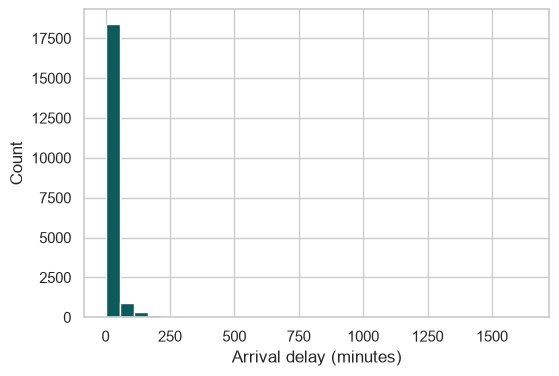

In [11]:
# (a) Histogram of your outcome variable.
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df['ArrDelayMinutes'].dropna(), bins=30, color='#0C5A5C', edgecolor='white')
ax.set_xlabel('Arrival delay (minutes)'); ax.set_ylabel('Count')
plt.show()

The distribution of arrival delays is strongly right-skewed, with most flights experiencing little or no delay and a few experiencing extremely long delays.

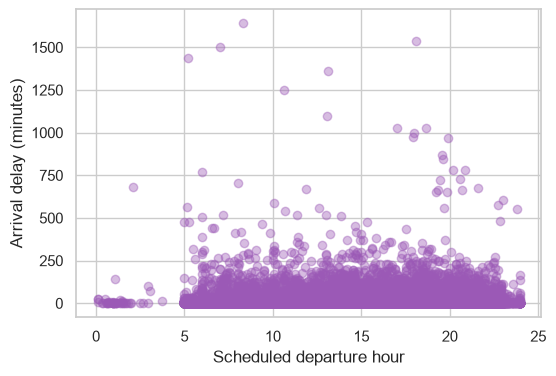

In [12]:
# (b) Scatter of the outcome against your main regressor.
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df['DepartureHour'], df['ArrDelayMinutes'], alpha=0.4, color='#9B59B6')
ax.set_xlabel('Scheduled departure hour'); ax.set_ylabel('Arrival delay (minutes)')
plt.show()

The scatter plot shows no strong linear relationship between scheduled departure hour and arrival delays. Extreme delays occurring at different times of the day.

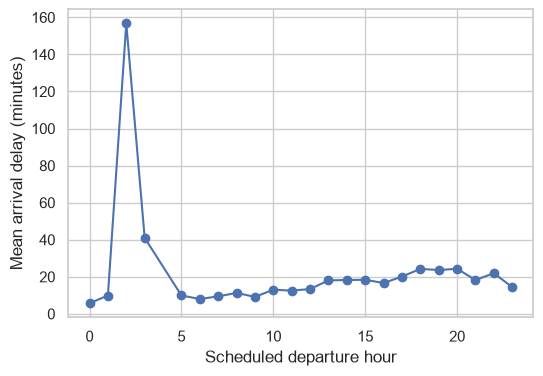

In [15]:
hourly = df.groupby(df.DepartureHour.astype(int)).ArrDelayMinutes.mean()
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(hourly.index, hourly.values, marker='o')
ax.set_xlabel('Scheduled departure hour'); ax.set_ylabel('Mean arrival delay (minutes)')
plt.show()

Average arrival delays generally increase from early morning to evening, there is an unusual spike around 2 a.m.

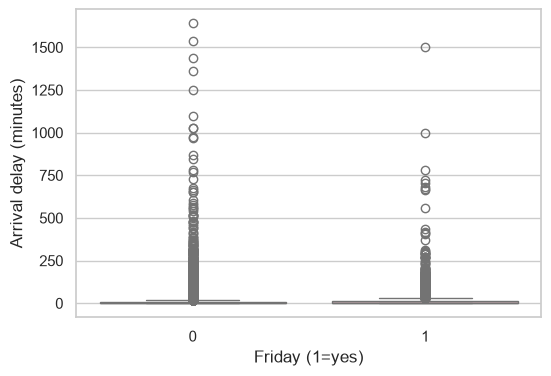

In [14]:
# (c) Box plot of the outcome across a group / category.
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x='Friday', y='ArrDelayMinutes', ax=ax, color='#D3ACB5')
ax.set_xlabel('Friday (1=yes)'); ax.set_ylabel('Arrival delay (minutes)')
plt.show()

Friday and non-Friday flights have similar delay distributions, both groups have many outliers.

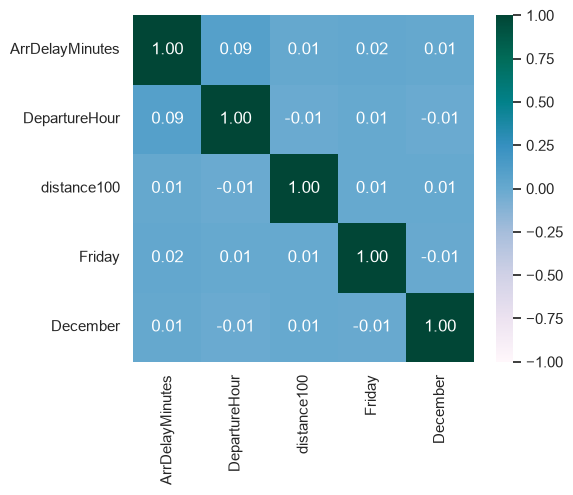

In [16]:
# (d) Correlation heatmap among your variables of interest.
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(df[myvars].corr(numeric_only=True), annot=True, fmt='.2f',
            cmap='PuBuGn', vmin=-1, vmax=1, ax=ax)
plt.show()

Scheduled departure hour has the strongest correlation with arrival delays (0.09), but the relationship is still weak.

**What surprised you?** In a sentence or two, compare the statistics and graphs above to the predictions you made in Building Block 2 Part 1 (the signs you expected, the pair you thought would be most correlated). Where were you right, and what was unexpected?

As expected, scheduled departure hour has a positive correlation with arrival delays, but the relationship is weaker than expected. We were also surprised by the unusually high average delay around 2 a.m.

<a id="methodology"></a>
<div style="border-left:7px solid #0C5A5C; background:#EFEAF0; padding:10px 20px; margin:14px 0 6px 0; border-radius:0 6px 6px 0;"><span style="font-size:19pt; color:#0C5A5C;"><b>5 &nbsp;Methodology / empirical model</b></span></div>

_Motivate and present the economic model behind your regression. This is where your question becomes an equation._

**Model.** Write the equation(s) you plan to estimate. For example:

$$ y_i = \beta_0 + \beta_1 x_{1i} + \beta_2 x_{2i} + \beta_3 x_{3i} + \dots + u_i $$

**Model choice.** Explain the thinking that led to this model. Then, for each piece:

- **What you include and why.** Each regressor needs a reason for being in the model.
- **What you would like to include but cannot.** Variables that matter but are not in your data &mdash; name them, and say which way they might bias your estimates (this is omitted-variable bias).

**Economic hypotheses and mechanisms.** For each regressor, make the case &mdash; on theory or intuition &mdash; for the sign and size of its effect, and name the **channel** that runs from the regressor to the outcome. The mechanism is the part that matters most.

| Regressor | Expected sign | Mechanism (why / through what channel) |
|---|:---:|---|
| `x1` | + / &minus; | _how x1 moves y, and why_ |
| `x2` | + / &minus; | _how x2 moves y, and why_ |
| `x3` | + / &minus; | _how x3 moves y, and why_ |

$$Y_i=\beta_0+\beta_1 DepartureHour_i+\beta_2 Distance100_i+\beta_3 Friday_i+\sum_m\gamma_m Month_{im}+\sum_a\delta_a Airline_{ia}+u_i$$

| Regressor | Expected sign | Mechanism |
|---|:---:|---|
| DepartureHour | + | Earlier disruptions may carry over to later flights. |
| distance100 | ? | Longer routes may encounter more disruptions but may also recover time. |
| Friday | + | Higher demand may increase congestion. |
| Month indicators | ? | Seasonal weather and demand differ. |
| Airline indicators | ? | Scheduling and operational efficiency differ across carriers. |
| DepartureHour × Friday (extension) | + / ? | Friday congestion may strengthen delay accumulation. |

Actual weather and airport congestion may increase delays, but their conditional correlations with scheduled hour are uncertain, so we don't know the direction of omitted-variable bias is . Departure delay and attributed delay minutes are excluded because of their mechanical relationship with the outcome. 

_You can write your model as a formula and fit it below to make sure it runs. This is a **first look** at the specification &mdash; the full results, interpretation, robustness, and inference go in the Results section, which we will build later._

In [17]:
# Preliminary specification (edit the formula to match your model).
# C(var) treats a variable as categorical; np.log(var) uses a log transform.
y = df['ArrDelayMinutes'].astype(float)
month = pd.get_dummies(df.Month, prefix='month', drop_first=True, dtype=float)
airline = pd.get_dummies(df.Reporting_Airline, prefix='airline', drop_first=True, dtype=float)
print('Month reference:', sorted(df.Month.unique())[0])
print('Airline reference:', sorted(df.Reporting_Airline.unique())[0])
X_short = sm.add_constant(pd.concat([df[['DepartureHour','distance100','Friday']], month], axis=1).astype(float))
m_short = sm.OLS(y, X_short).fit()
X_long = sm.add_constant(pd.concat([df[['DepartureHour','distance100','Friday']], month, airline], axis=1).astype(float))
m_long = sm.OLS(y, X_long).fit()
m_long.summary()

Month reference: 1
Airline reference: 9E


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        ArrDelayMinutes   R-squared:                       0.022
Model:                            OLS   Adj. R-squared:                  0.020
Method:                 Least Squares   F-statistic:                     15.71
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           1.19e-74
Time:                        15:21:21   Log-Likelihood:            -1.0806e+05
No. Observations:               20000   AIC:                         2.162e+05
Df Residuals:                   19971   BIC:                         2.164e+05
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             3.0854      2.836      1.088      0.277      -2.474       8.645
DepartureHour     0.9377      0.077     12.215      0.000       0.787       1.088
distance100      -0.0124      0.071     -0.175      0.861      -0.151       0.126
Friday            2.2603      1.063      2.127      0.033       0.177       4.343
month_2          -8.0286      1.934     -4.152      0.000     -11.818      -4.239
month_3          -4.0636      1.901     -2.137      0.033      -7.790      -0.337
month_4          -6.8675      1.902     -3.610      0.000     -10.596      -3.139
month_5           1.5353      1.877      0.818      0.413      -2.144       5.215
month_6          -3.5125      1.862     -1.887      0.059      -7.161       0.136
month_7           3.3822      1.861      1.817      0.069      -0.266       7.031
month_8          -1.8177      1.848     -0.983      0.325      -5.441       1.805
month_9         -10.2113      1.898     -5.381      0.000     -13.931      -6.492
month_10        -11.8947      1.866     -6.376      0.000     -15.552      -8.238
month_11         -9.4161      1.900     -4.955      0.000     -13.141      -5.691
month_12         -2.1334      1.910     -1.117      0.264      -5.878       1.611
airline_AA       12.0005      2.528      4.748      0.000       7.046      16.955
airline_AS        2.5188      3.117      0.808      0.419      -3.591       8.628
airline_B6        7.6416      3.131      2.441      0.015       1.505      13.778
airline_DL        1.2417      2.521      0.493      0.622      -3.699       6.183
airline_F9       10.5796      3.183      3.324      0.001       4.342      16.818
airline_G4       12.6873      3.794      3.344      0.001       5.252      20.123
airline_HA       -1.4109      4.196     -0.336      0.737      -9.636       6.814
airline_MQ        3.2701      2.955      1.107      0.268      -2.521       9.062
airline_NK        2.9440      3.090      0.953      0.341      -3.112       9.000
airline_OH        8.2661      3.127      2.644      0.008       2.137      14.395
airline_OO        4.2278      2.569      1.646      0.100      -0.808       9.264
airline_UA        4.4813      2.595      1.727      0.084      -0.606       9.568
airline_WN        0.7861      2.446      0.321      0.748      -4.009       5.581
airline_YX       -2.5038      2.953     -0.848      0.396      -8.292       3.284
==============================================================================
Omnibus:                    34027.414   Durbin-Watson:                   1.981
Prob(Omnibus):                  0.000   Jarque-Bera (JB):         43923016.765
Skew:                          11.656   Prob(JB):                         0.00
Kurtosis:                     231.395   Cond. No.                         399.
================================================================

### Results and robustness

In [18]:
emp_bias = m_short.params['DepartureHour'] - m_long.params['DepartureHour']
print(f"Empirical difference (short - long): {emp_bias:.4f}")
comparison = pd.DataFrame({
    'Departure hour coefficient': [m_short.params['DepartureHour'], m_long.params['DepartureHour']],
    'R-squared': [m_short.rsquared, m_long.rsquared]
}, index=['Short model','Long model'])
comparison.round(4)

Empirical difference (short - long): 0.0095


,Departure hour coefficient,R-squared
Short model,0.947,0.015
Long model,0.938,0.022


Classical and Robust Standard Errors

In [21]:
X = X_long
model = sm.OLS(y, X)

ols_classic = model.fit()
ols_hc0 = model.fit(cov_type="HC0")

print("Classical (assumes constant spread")
print(ols_classic.summary().tables[1])

print("\nRobust (HC0)")
print(ols_hc0.summary().tables[1])

Classical (assumes constant spread
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             3.0854      2.836      1.088      0.277      -2.474       8.645
DepartureHour     0.9377      0.077     12.215      0.000       0.787       1.088
distance100      -0.0124      0.071     -0.175      0.861      -0.151       0.126
Friday            2.2603      1.063      2.127      0.033       0.177       4.343
month_2          -8.0286      1.934     -4.152      0.000     -11.818      -4.239
month_3          -4.0636      1.901     -2.137      0.033      -7.790      -0.337
month_4          -6.8675      1.902     -3.610      0.000     -10.596      -3.139
month_5           1.5353      1.877      0.818      0.413      -2.144       5.215
month_6          -3.5125      1.862     -1.887      0.059      -7.161       0.136
month_7           3.3822      1.861      1.817      0.069      

In [22]:
comparison = pd.DataFrame({
    'Coefficient': [m.params['DepartureHour'] for m in [m_short, ols_classic, ols_hc0]],
    'SE': [m.bse['DepartureHour'] for m in [m_short, ols_classic, ols_hc0]],
    'p-value': [m.pvalues['DepartureHour'] for m in [m_short, ols_classic, ols_hc0]],
    'N': [int(m.nobs) for m in [m_short, ols_classic, ols_hc0]],
    'R-squared': [m.rsquared for m in [m_short, ols_classic, ols_hc0]]
}, index=['Short','Main classical','Main HC0'])
comparison.round(4)

,Coefficient,SE,p-value,N,R-squared
Short,0.947,0.077,0.000,20000,0.015
Main classical,0.938,0.077,0.000,20000,0.022
Main HC0,0.938,0.082,0.000,20000,0.022


residual diagnostics

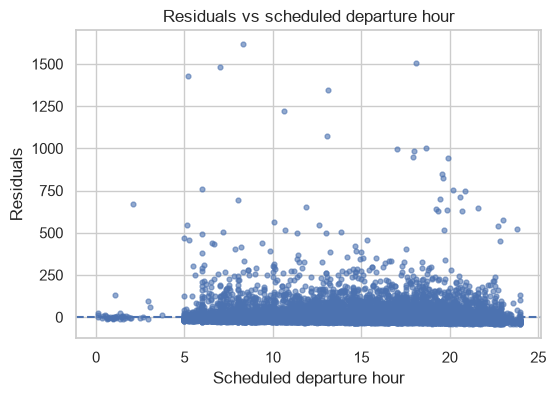

In [23]:
plt.figure(figsize=(6,4))
plt.scatter(df.DepartureHour, ols_classic.resid, s=12, alpha=0.6)
plt.axhline(0, ls="--")
plt.title("Residuals vs scheduled departure hour")
plt.xlabel("Scheduled departure hour"); plt.ylabel("Residuals")
plt.show()

In [24]:
bp_lm, bp_lm_p, _, _ = sm_diagnostic.het_breuschpagan(ols_classic.resid, X)
white_lm, white_lm_p, _, _ = sm_diagnostic.het_white(ols_classic.resid, X)
print({"BP_p": float(bp_lm_p), "White_p": float(white_lm_p)})
alpha = 0.05
print(f"Decision @ {alpha*100:.0f}%: " + ("Reject homoskedasticity" if (bp_lm_p < alpha or white_lm_p < alpha) else "No strong evidence against homoskedasticity"))

{'BP_p': 1.375373825185759e-05, 'White_p': 0.0004134007833103098}
Decision @ 5%: Reject homoskedasticity


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/stats/diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


In [25]:
X_interaction = X_long.copy()
X_interaction['DepartureHour_x_Friday'] = df.DepartureHour * df.Friday
m_interaction = sm.OLS(y, X_interaction).fit(cov_type="HC0")
print(m_interaction.summary().tables[1])
print('Non-Friday slope:', m_interaction.params['DepartureHour'])
print('Friday slope:', m_interaction.params['DepartureHour'] + m_interaction.params['DepartureHour_x_Friday'])

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      2.7637      2.328      1.187      0.235      -1.799       7.326
DepartureHour              0.9629      0.085     11.290      0.000       0.796       1.130
distance100               -0.0123      0.059     -0.207      0.836      -0.129       0.104
Friday                     4.4677      3.801      1.175      0.240      -2.983      11.918
month_2                   -8.0353      2.247     -3.577      0.000     -12.438      -3.632
month_3                   -4.0761      2.248     -1.813      0.070      -8.482       0.330
month_4                   -6.8859      2.056     -3.350      0.001     -10.915      -2.857
month_5                    1.5265      2.306      0.662      0.508      -2.993       6.046
month_6                   -3.5154      1.965     -1.789      0.074      -7.367       0.336

<a id="references"></a>
<div style="border-left:7px solid #0C5A5C; background:#EFEAF0; padding:10px 20px; margin:14px 0 6px 0; border-radius:0 6px 6px 0;"><span style="font-size:19pt; color:#0C5A5C;"><b>6 &nbsp;References</b></span></div>

_At least three sources (news or journal articles) on a similar question, each with one line on what they found. No particular citation format is required &mdash; just be consistent._

1. Tirtha, Sudipta Dey, Tanmoy Bhowmik, and Naveen Eluru. “Flight-Level Analysis of Departure Delay and Arrival Delay Using Copula-Based Joint Framework.” Transportation Research Record, 2023. The study found that arrival delays are lower during the morning and midday than at other times of the day.
https://doi.org/10.1177/03611981221130031

2. Wu, Cheng-Lung. “Inherent Delays and Operational Reliability of Airline Schedules.” Journal of Air Transport Management, 2005. The study found that morning delays tend to carry over to later flights unless sufficient buffer time is included in airline schedules.
https://doi.org/10.1016/j.jairtraman.2005.01.005

3. Hsiao, Chieh-Yu, and Mark Hansen. “Econometric Analysis of U.S. Airline Flight Delays with Time-of-Day Effects.” Transportation Research Record, 2006. The study found that morning queuing delays have a greater impact on average daily flight delays than afternoon or evening queuing delays.
https://doi.org/10.1177/0361198106195100113

AI disclosure: We asked ChatGPT to check our codes for the graphs and the regression and help interpret the exploratory regression. We ran the exploratory model ourselves.

<hr style="border-top:3px solid #0C5A5C; margin:18px 0;">

**Before you submit:** hide the code and read the document top to bottom &mdash; it should stand on its own as a research paper. Then export to HTML and submit **both** files.

```
# Run in a terminal, or in a cell with a leading ! , from the notebook folder:
jupyter nbconvert --to html YOUR_NOTEBOOK.ipynb
```

_AI disclosure: add one sentence stating exactly what you asked AI and what you did yourself._